In [1]:
# This notebook is 
#get common train/validation/test data
import pandas as pd
train_df = pd.read_csv("../covid/splits/train.csv")
val_df = pd.read_csv("../covid/splits/validation.csv")
test_df = pd.read_csv("../covid/splits/test.csv")

In [2]:
train_gen_df = train_df.copy()
val_gen_df = val_df.copy()
test_gen_df = test_df.copy()

train_gen_df["target"] = train_gen_df["target"].astype(str)
val_gen_df["target"] = val_gen_df["target"].astype(str)
test_gen_df["target"] = test_gen_df["target"].astype(str)

In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input

# TRAIN : preprocessing VGG16 + Data Augmentation
train_datagen_e6 = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

# VALIDATION : preprocessing VGG16 uniquement
val_datagen_e6 = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
COLOR_MODE = "rgb"

train_generator_e6 = train_datagen_e6.flow_from_dataframe(
    dataframe=train_gen_df,
    x_col="filepath",
    y_col="target",
    target_size=IMAGE_SIZE,
    color_mode=COLOR_MODE,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_generator_e6 = val_datagen_e6.flow_from_dataframe(
    dataframe=val_gen_df,
    x_col="filepath",
    y_col="target",
    target_size=IMAGE_SIZE,
    color_mode=COLOR_MODE,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_generator_e6 = val_datagen_e6.flow_from_dataframe(
    dataframe=test_gen_df,
    x_col="filepath",
    y_col="target",
    target_size=IMAGE_SIZE,
    color_mode=COLOR_MODE,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 13545 validated image filenames belonging to 2 classes.
Found 3387 validated image filenames belonging to 2 classes.
Found 4233 validated image filenames belonging to 2 classes.


In [4]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

base_model_e6 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_e6.trainable = False

model_e6 = Sequential([
    base_model_e6,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

In [5]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model_e6.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

early_stopping_e6 = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

checkpoint_e6 = ModelCheckpoint(
    "E6_VGG16_TL_DA_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [6]:
history_e6 = model_e6.fit(
    train_generator_e6,
    validation_data=val_generator_e6,
    epochs=5,
    callbacks=[early_stopping_e6, checkpoint_e6],
    verbose=1
)

Epoch 1/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8705 - auc: 0.8523 - loss: 0.3352 - precision: 0.6857 - recall: 0.4468   
Epoch 1: val_loss improved from None to 0.21274, saving model to E6_VGG16_TL_DA_best.keras

Epoch 1: finished saving model to E6_VGG16_TL_DA_best.keras
424/424 ━━━━━━━━━━━━━━━━━━━━ 2884s 7s/step - accuracy: 0.8705 - auc: 0.8523 - loss: 0.3352 - precision: 0.6857 - recall: 0.4468 - val_accuracy: 0.9099 - val_auc: 0.9569 - val_loss: 0.2127 - val_precision: 0.9391 - val_recall: 0.5060
Epoch 2/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9103 - auc: 0.9343 - loss: 0.2268 - precision: 0.7978 - recall: 0.6361   
Epoch 2: val_loss improved from 0.21274 to 0.17457, saving model to E6_VGG16_TL_DA_best.keras

Epoch 2: finished saving model to E6_VGG16_TL_DA_best.keras
424/424 ━━━━━━━━━━━━━━━━━━━━ 2849s 7s/step - accuracy: 0.9103 - auc: 0.9343 - loss: 0.2268 - precision: 0.7978 - recall: 0.6361 - val_accuracy: 0.9339 - val_auc: 0.9668 - val_loss: 0.1

In [ ]:
#from tensorflow.keras.models import load_model

#model_e6_best = load_model("E6_VGG16_TL_DA_best.keras")

#print("Meilleur modèle E6 rechargé.")

In [8]:
import numpy as np

val_generator_e6.reset()

y_prob_e6 = model_e6.predict(
    val_generator_e6,
    verbose=1
).ravel()

y_pred_e6 = (y_prob_e6 >= 0.5).astype(int)
y_true_e6 = val_generator_e6.classes

print("Nombre d'images :", len(y_true_e6))
print("Seuil utilisé : 0.5")

106/106 ━━━━━━━━━━━━━━━━━━━━ 517s 5s/step
Nombre d'images : 3387
Seuil utilisé : 0.5


In [9]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

cm_e6 = confusion_matrix(y_true_e6, y_pred_e6)

print("Matrice de confusion :")
print(cm_e6)

print("\nClassification report :")
print(
    classification_report(
        y_true_e6,
        y_pred_e6,
        target_names=["Non-COVID", "COVID"],
        digits=4
    )
)

report_e6 = classification_report(
    y_true_e6,
    y_pred_e6,
    target_names=["Non-COVID", "COVID"],
    output_dict=True
)

report_e6_df = pd.DataFrame(report_e6).transpose()
display(report_e6_df)

report_e6_df.to_csv("E6_classification_report.csv")

Matrice de confusion :
[[2773   35]
 [ 147  432]]

Classification report :
              precision    recall  f1-score   support

   Non-COVID     0.9497    0.9875    0.9682      2808
       COVID     0.9251    0.7461    0.8260       579

    accuracy                         0.9463      3387
   macro avg     0.9374    0.8668    0.8971      3387
weighted avg     0.9455    0.9463    0.9439      3387



,precision,recall,f1-score,support
Non-COVID,0.949658,0.987536,0.968226,2808.000000
COVID,0.925054,0.746114,0.826004,579.000000
accuracy,0.946265,0.946265,0.946265,0.946265
macro avg,0.937356,0.866825,0.897115,3387.000000
weighted avg,0.945452,0.946265,0.943914,3387.000000


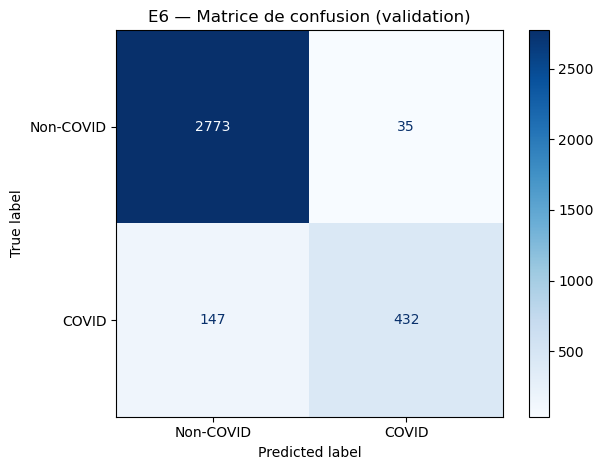

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_e6,
    display_labels=["Non-COVID", "COVID"]
)

disp.plot(values_format="d", cmap="Blues" )
plt.title("E6 — Matrice de confusion (validation)")
plt.tight_layout()

plt.savefig(
    "E6_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

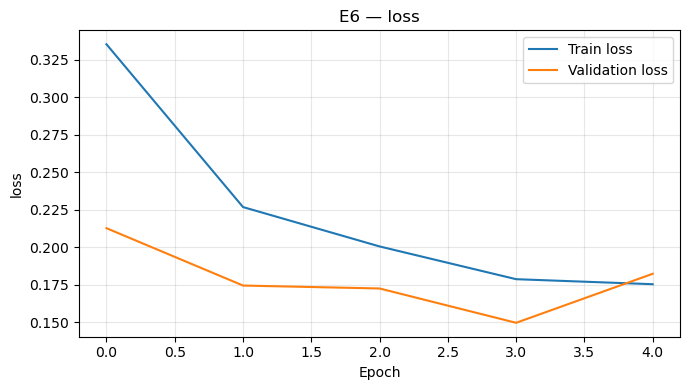

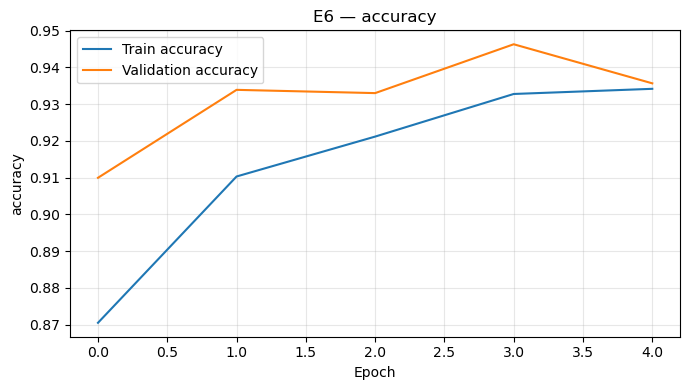

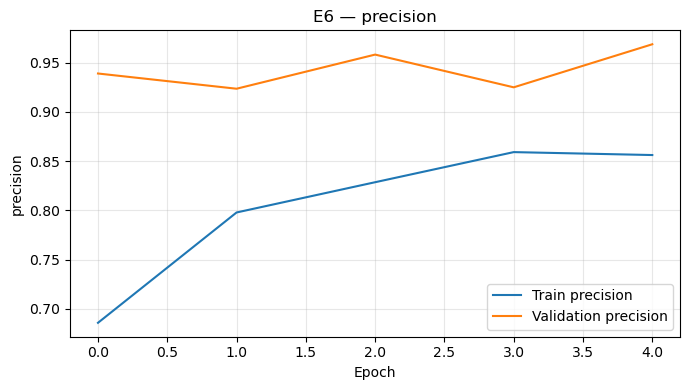

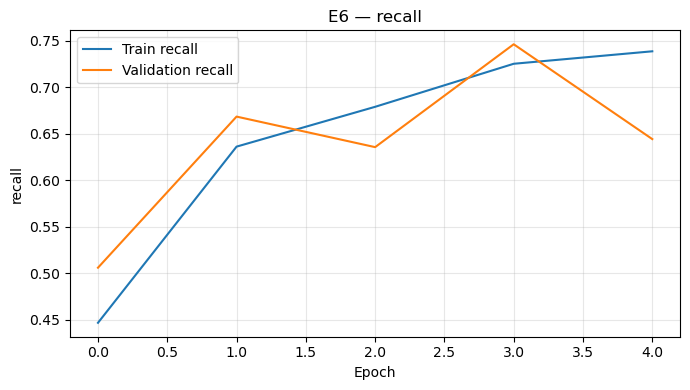

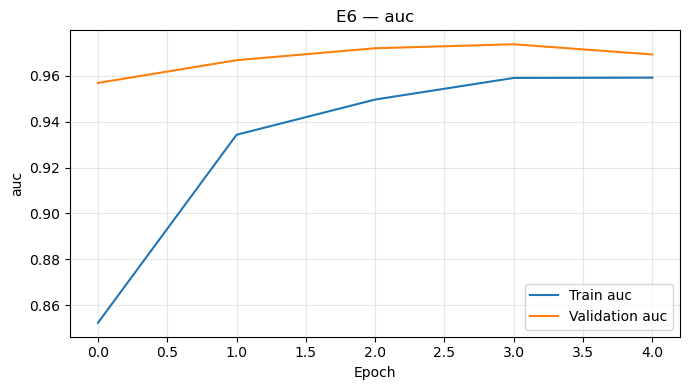

In [14]:
metrics = ["loss", "accuracy", "precision", "recall", "auc"]

for metric in metrics:
    plt.figure(figsize=(7, 4))

    plt.plot(
        history_e6.history[metric],
        label=f"Train {metric}"
    )

    plt.plot(
        history_e6.history[f"val_{metric}"],
        label=f"Validation {metric}"
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"E6 — {metric}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"E6_{metric}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()